In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

dataset = np.load('dataset3.npz')

X_train, X_test = dataset['X_train'], dataset['X_test']
y_train, y_test = dataset['y_train'], dataset['y_test']

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("accuracy (test)", accuracy_score(y_test, y_pred))


print("accuracy (train)", accuracy_score(y_train, y_pred_train))

# baseline: always predicting the larger class
for name, y in [("train", y_train), ("test", y_test)]:
    labels, counts = np.unique(y, return_counts=True)
    print(name, dict(zip(labels, counts)), "majority baseline:", counts.max() / counts.sum())

print("predicted labels (train):", np.unique(y_pred_train, return_counts=True))


print("learned weights:", model.coef_, model.intercept_)

accuracy (test) 0.63
accuracy (train) 0.5925
train {np.int64(0): np.int64(237), np.int64(1): np.int64(163)} majority baseline: 0.5925
test {np.int64(0): np.int64(63), np.int64(1): np.int64(37)} majority baseline: 0.63
predicted labels (train): (array([0]), array([400]))
learned weights: [[-0.19548198  0.09608107]] [-0.3732732]


mean: [0.01510594 0.00677153]
std:  [0.58668804 0.63270403]


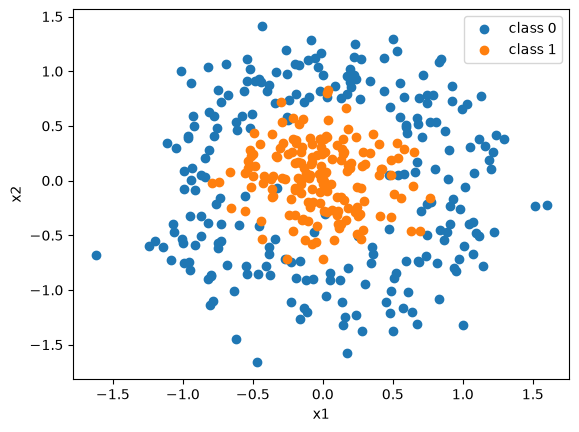

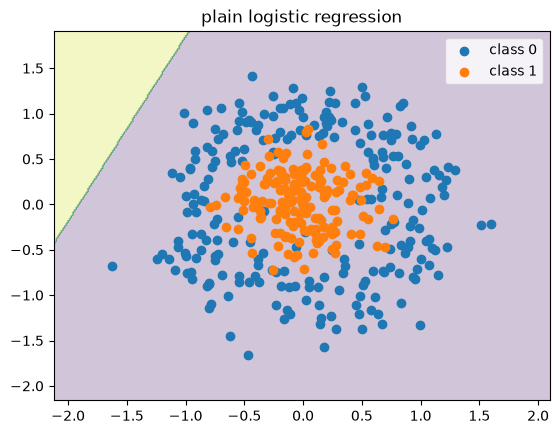

In [14]:
print("mean:", X_train.mean(axis=0))
print("std: ", X_train.std(axis=0))

plt.figure()

plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], label='class 0')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], label='class 1')


plt.xlabel('x1'); plt.ylabel('x2'); plt.legend()
plt.show()

def plot_boundary(model, X, y, title):
    x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300)
    x2 = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300)

    
    xx1, xx2 = np.meshgrid(x1, x2)
    zz = model.predict(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)
    
    plt.figure()
    
    plt.contourf(xx1, xx2, zz, alpha=0.25)
    plt.scatter(X[y == 0, 0], X[y == 0, 1], label='class 0')
    
    plt.scatter(X[y == 1, 0], X[y == 1, 1], label='class 1')
    plt.title(title); plt.legend()


    
    plt.show()

plot_boundary(model, X_train, y_train, "plain logistic regression")

degree  1: validation accuracy = 0.592
degree  2: validation accuracy = 0.883
degree  3: validation accuracy = 0.883
degree  4: validation accuracy = 0.900
degree  5: validation accuracy = 0.900
degree  6: validation accuracy = 0.892
degree  7: validation accuracy = 0.892
degree  8: validation accuracy = 0.892
degree  9: validation accuracy = 0.892
degree 10: validation accuracy = 0.892


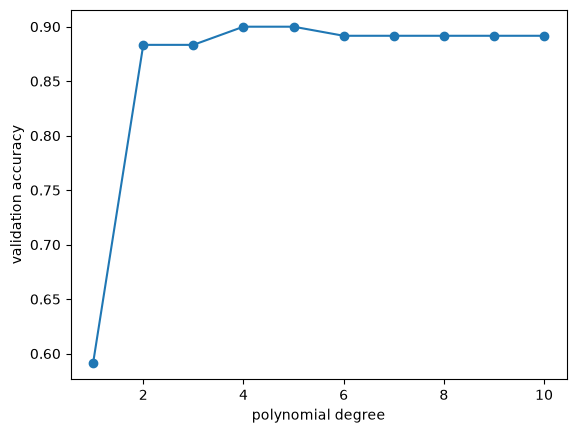

In [15]:
def make_model(degree):
    return make_pipeline(
        PolynomialFeatures(degree, include_bias=False),   
        StandardScaler(),
        LogisticRegression(max_iter=5000),
    )

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.3, random_state=0, stratify=y_train)

degrees = list(range(1, 11))
val_acc = []
for d in degrees:
    m = make_model(d).fit(X_tr, y_tr)
    val_acc.append(accuracy_score(y_val, m.predict(X_val)))
    print(f"degree {d:2d}: validation accuracy = {val_acc[-1]:.3f}")

plt.plot(degrees, val_acc, marker='o')
plt.xlabel("polynomial degree"); plt.ylabel("validation accuracy")
plt.show()

accuracy (train) 0.93
accuracy (test)  0.92


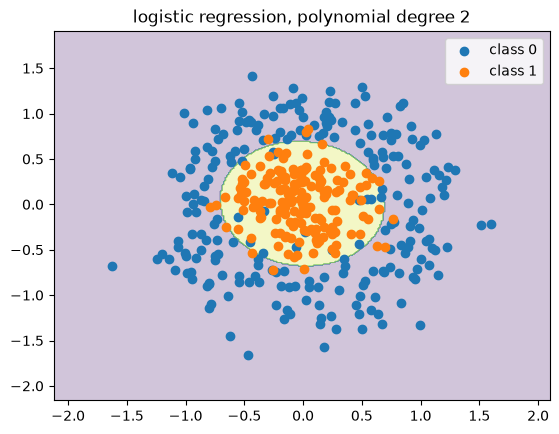

In [16]:
best_degree = 2     

final = make_model(best_degree).fit(X_train, y_train)
print("accuracy (train)", accuracy_score(y_train, final.predict(X_train)))


print("accuracy (test) ", accuracy_score(y_test, final.predict(X_test)))

plot_boundary(final, X_train, y_train, f"logistic regression, polynomial degree {best_degree}")

## What would be the baseline (e.g. if random guessing) for the accuracy on this particular dataset?


#### If we guess randomly it gives around 0.5 or 0.52 if guesses follow the class proportions. The majority class is always predicted by a stricter baseline and as the training set has 237 samples of class 0 and 163 samples of class 1 so it gives 0.5925 on train and also it gives 0.63 on test. Basically the model's accuracies (0.5925 train, 0.63 test) are exactly these baseline values.


## Why does it perform so poorly?

#### The problem is that the decision boundary is linear for this program, and the scatter plot indicates that class 1 forms a compact cluster at the center while class 0 surrounds it. The problem occurs when the linear decision boundary is outside of the points and flags all the records as class 0. The model is obviously underfitting because the accuracy of the training set is less than the test set so we need to create more polynomial features to turn the decision boundary from linear to non-linear form

## How would you solve the issue, i.e., getting a model that properly classifies the dataset?

#### What I did was basically add more polynomial features like Phi(x) = (x1, x2, x1^2, x1*x2, x2^2, ...) to make a non-linear decision boundary. The same logistic regression model is applied but now the decision boundary is curved and performs the classification better avoiding high bias risk. I chose the degree on the validation set which of 30% of training set as the degree is a hyperparameter. According to the findings, the largest jump was from degree 1 to 2 and higher degrees added little change so I decided to choose the simplest model with degree 2 as x1^2 and x2^2 are well enough to create a circular boundary. Based on what I observed degree 2 achieves 0.93 train and 0.92 test accuracy and creates a non-linear decision boundary around class 1 and there is no risk of overfitting too as the train and test accuracies are quite close. The remaining error is due to overlap of classes at the edges.